In [1]:
import numpy as np 
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform
from tqdm import tqdm

## 度量不同脑区的回声物种差异

In [2]:
scdata = sc.read_h5ad('/home/rsun@ZHANGroup.local/sly_data/data/final_anno.h5ad')
scdata

AnnData object with n_obs × n_vars = 338818 × 3000
    obs: 'species', 'tissues', 'samples', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'cluster', 'celltype', 'coarse_celltype'
    var: 'gene_ids', 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'celltype_colors', 'cluster_colors', 'coarse_celltype_colors', 'dendrogram_leiden', 'hvg', 'leiden', 'log1p', 'neighbors', 'pca', 'samples_colors', 'species_colors', 'tissues_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap', 'harmony_0', 'umap_0'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [16]:


metric_key = 'euclidean'
tissue_res = {}
for tissue in scdata.obs.tissues.unique():

    res_dic = {}

    adata = scdata[scdata.obs['tissues'] == tissue,:] # tissue spcific data
    for species in ['CY','JT','T','QF','M']:
        species_idx = adata.obs['species'] == species 
        subdata = adata[species_idx,:] 

        # idx = np.arange(subdata.shape[0])
        # sel_idx = np.random.choice(idx, size = 3000)
        # meta_cell = subdata[sel_idx].obsm['X_pca_harmony'].mean(axis = 0)
        meta_cell = subdata.obsm['X_pca_harmony'].mean(axis = 0)
        res_dic[species] = meta_cell 
        
    
    res_df = pd.DataFrame(res_dic).T
    sim_df = squareform(pdist(res_df, metric=metric_key))

    if tissue == 'HM':
        hm_sim = sim_df
    score = 2*(sim_df[:3,3:].mean()) - (sim_df[:3,:3].sum()/6 + sim_df[3:,3:].sum()/2)
    tissue_res[tissue] = score 

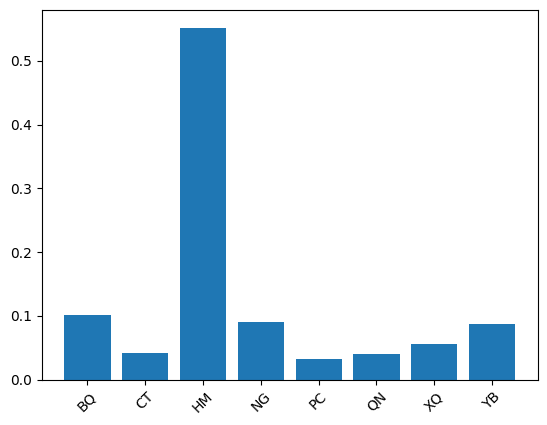

In [42]:
diff = np.array(list(tissue_res.values()))
tmp = np.exp(diff/5)
tmp = tmp/tmp.sum()
plt.bar(x =tissue_res.keys(), height = tmp)
plt.xticks(rotation = 45)
plt.show()

In [44]:
from scipy import stats
import numpy as np

data = np.concatenate([tmp[:2], tmp[3:]]) 
mu0 = tmp[2]

delta = data - mu0

stat, p_two_tailed = stats.wilcoxon(delta, alternative='two-sided')

mean_diff = np.max(delta)
if mean_diff < 0:
    p_one_tailed = p_two_tailed / 2
else:
    p_one_tailed = 1 - p_two_tailed / 2

print(f"Sample median: {mean_diff :.4f}")
print(f"Wilcoxon stat: {stat:.4f}")
print(f"One-tailed p-value (H1: median < {mu0}): {p_one_tailed:.4f}")

alpha = 0.05
if p_one_tailed < alpha and mean_diff < 0:
    print(f"✅ 拒绝 H0：中位数显著低于 {mu0}")
else:
    print(f"❌ 无法拒绝 H0：中位数不显著低于 {mu0}")

Sample median: -0.4511
Wilcoxon stat: 0.0000
One-tailed p-value (H1: median < 0.5522667443367019): 0.0078
✅ 拒绝 H0：中位数显著低于 0.5522667443367019


## p值

In [3]:

metric_key = 'euclidean' #'cosine' #'cosine'

data_list = []
for k in range(20):
    tissue_res = {}
    for tissue in scdata.obs.tissues.unique():

        res_dic = {}

        adata = scdata[scdata.obs['tissues'] == tissue,:] # tissue spcific data
        for species in ['CY','JT','T','QF','M']:
            species_idx = adata.obs['species'] == species 
            subdata = adata[species_idx,:] 

            idx = np.arange(subdata.shape[0])
            sel_idx = np.random.choice(idx, size = 3000)
            meta_cell = subdata[sel_idx].obsm['X_pca_harmony'].mean(axis = 0)
            # meta_cell = subdata.obsm['X_pca_harmony'].mean(axis = 0)
            res_dic[species] = meta_cell 
            
        
        res_df = pd.DataFrame(res_dic).T
        sim_df = squareform(pdist(res_df, metric=metric_key))

        if tissue == 'HM':
            hm_sim = sim_df
        score = 2*(sim_df[:3,3:].mean()) - (sim_df[:3,:3].sum()/6 + sim_df[3:,3:].sum()/2)
        tissue_res[tissue] = score 

    data_list.append(tissue_res)
df = pd.DataFrame(data_list)
df

,BQ,CT,HM,NG,PC,QN,XQ,YB
0,3.093108,-0.925415,11.780704,2.521908,-2.455228,-0.676048,0.816268,2.567808
1,3.231637,-0.993147,11.392260,2.553531,-2.118416,-1.428549,0.315938,2.883746
2,3.575801,-0.952303,11.984660,3.250692,-2.039686,-1.273418,0.803470,2.408819
3,3.451257,-0.952572,11.333537,2.249903,-2.188783,-0.872193,0.481133,2.489035
4,3.292902,-1.032039,11.192215,3.376181,-2.229207,-0.942805,0.719661,2.520062
5,3.095217,-0.959870,12.117483,2.888008,-1.966378,-1.006092,0.337757,2.903716
6,3.667628,-0.869038,11.324386,3.584666,-2.068643,-1.465515,0.276595,2.666351
7,3.987663,-0.785114,12.053218,2.839307,-1.979962,-1.434068,0.318765,2.589809
8,3.180439,-0.955483,11.599054,2.150123,-2.366113,-0.918770,0.424733,2.749204
9,3.688580,-1.066573,12.070921,3.938822,-2.077080,-0.982331,0.596139,2.624498


In [4]:
X = df.values 
t = 5
exp_x = np.exp(X/t)
exp_sum = exp_x.sum(axis = 1, keepdims = True)
prob = exp_x / exp_sum
df = pd.DataFrame(prob, index = df.index, columns = df.columns)

In [7]:
import numpy as np
import pandas as pd
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests
from scipy import stats

hippo = df['HM'].values
other_regions = [col for col in df.columns if col != 'HM']

pvals = []
stat_idx= []

for region in other_regions:
    
    y = df[region].values
    # delta = y - hippo
    # print(region, delta.min())
    # stat, p_one_sided = stats.wilcoxon(delta, alternative='less')
    # # 单侧 t 检验：注意 ttest_ind 默认是双侧
    t_stat, p_two_sided = ttest_ind(hippo, y, equal_var=False)  # 可设 equal_var=False 用 Welch's t-test
    
    # 转换为单侧 p 值（因为我们关心 hippo > region）
    if t_stat > 0:
        p_one_sided = p_two_sided / 2
    else:
        p_one_sided = 1 - p_two_sided / 2  # 实际不会显著，但逻辑完整
    
    stat_idx.append(t_stat)
    pvals.append(p_one_sided)

# FDR 校正（Benjamini-Hochberg）
reject, pvals_corrected, _, _ = multipletests(pvals, alpha=0.05, method='fdr_bh')

# 整理结果
results = pd.DataFrame({
    'Comparison': [f'HM vs {r}' for r in other_regions],
    't_statistic': stat_idx,
    'p_raw': pvals,
    'p_fdr': pvals_corrected,
    'significant (FDR<0.05)': reject
})

results

,Comparison,t_statistic,p_raw,p_fdr,significant (FDR<0.05)
0,HM vs BQ,57.297721,8.578429e-25,1.321647e-24,True
1,HM vs CT,66.428051,1.380704e-24,1.380704e-24,True
2,HM vs NG,55.659053,7.928677e-28,5.550074e-27,True
3,HM vs PC,67.582021,1.000157e-24,1.321647e-24,True
4,HM vs QN,66.374918,1.071795e-24,1.321647e-24,True
5,HM vs XQ,64.260488,1.132840e-24,1.321647e-24,True
6,HM vs YB,58.854844,2.067705e-25,7.236968e-25,True


In [8]:
results.to_csv('tissues_diff_p.csv')